TAHAP PENGOLAHAN CITRA

In [2]:
# Import Library

import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, precision_score, recall_score, f1_score

import joblib

Label      : Baik
Nama File  : IMG_20260402_221214.jpg


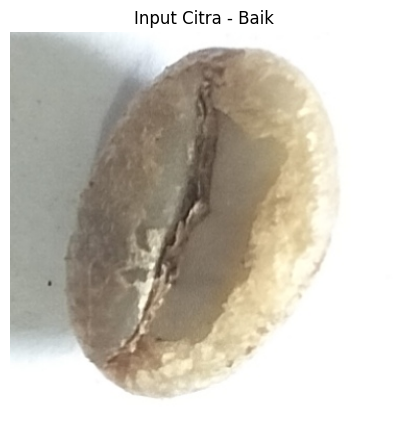

In [3]:
# INPUT CITRA

for label in ['baik', 'buruk']:

    path = os.path.join("../dataset", label)
    files = os.listdir(path)

    for file in files:

        img_path = os.path.join(path, file)
        img = cv2.imread(img_path)

        if img is None:
            continue

        print("Label      :", label.capitalize())
        print("Nama File  :", file)

        plt.figure(figsize=(5,5))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(f"Input Citra - {label.capitalize()}")
        plt.axis("off")
        plt.show()

        break

    break

Ukuran Citra Asli   : (370, 372, 3)
Ukuran Setelah Resize : (224, 224, 3)


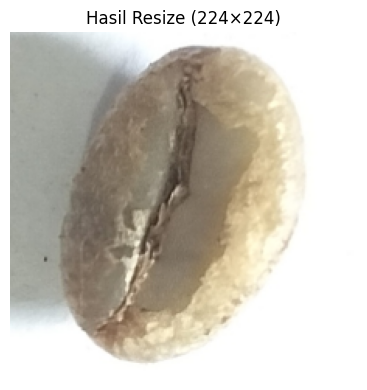

In [4]:
# RESIZE CITRA

img_resize = cv2.resize(img, (224, 224))

print("Ukuran Citra Asli   :", img.shape)
print("Ukuran Setelah Resize :", img_resize.shape)

plt.figure(figsize=(8,4))

plt.imshow(cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB))
plt.title("Hasil Resize (224×224)")
plt.axis("off")

plt.tight_layout()
plt.show()

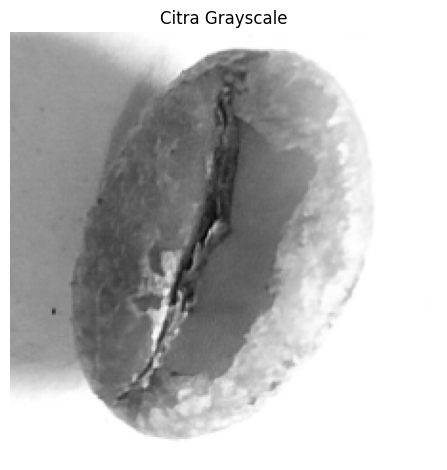

In [5]:
# KONVERSI GRAYSCALE

gray = cv2.cvtColor(img_resize, cv2.COLOR_BGR2GRAY)


plt.imshow(gray, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")

plt.tight_layout()
plt.show()

Red   (R) : 195.68
Green (G) : 189.64
Blue  (B) : 177.49


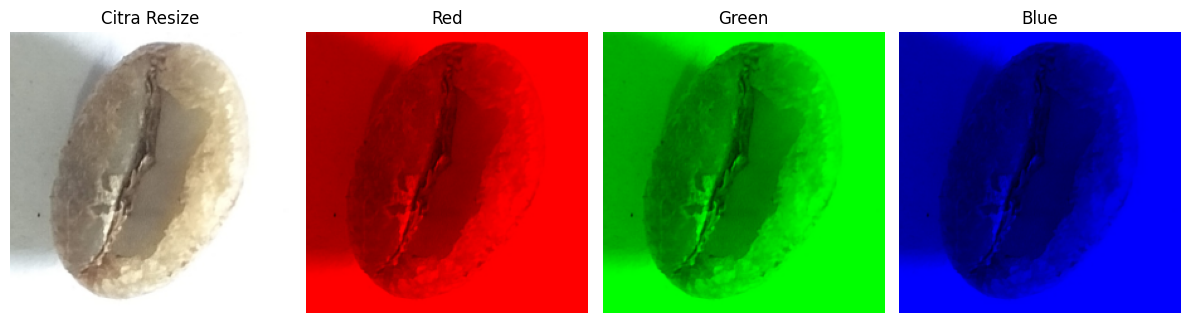

In [6]:
# EKSTRAKSI FITUR WARNA RGB

mean_r = np.mean(img_resize[:, :, 2])
mean_g = np.mean(img_resize[:, :, 1])
mean_b = np.mean(img_resize[:, :, 0])

print(f"Red   (R) : {mean_r:.2f}")
print(f"Green (G) : {mean_g:.2f}")
print(f"Blue  (B) : {mean_b:.2f}")

rgb = cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB)

R = rgb.copy()
R[:, :, 1] = 0
R[:, :, 2] = 0

G = rgb.copy()
G[:, :, 0] = 0
G[:, :, 2] = 0

B = rgb.copy()
B[:, :, 0] = 0
B[:, :, 1] = 0

plt.figure(figsize=(12,4))

plt.subplot(1,4,1)
plt.imshow(rgb)
plt.title("Citra Resize")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(R)
plt.title("Red")

plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(G)
plt.title("Green")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(B)
plt.title("Blue")
plt.axis("off")

plt.tight_layout()
plt.show()

Contrast      : 48.9948
Energy        : 0.2930
Homogeneity   : 0.5041
Dissimilarity : 3.1613
Correlation   : 0.9924
ASM           : 0.0858


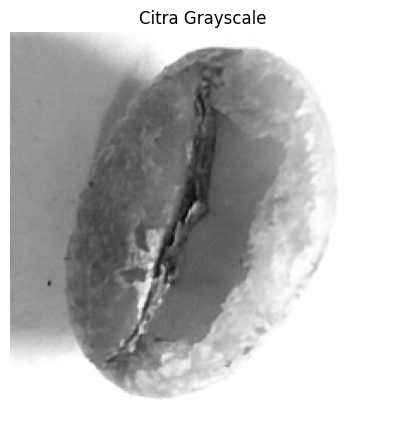

In [7]:
# EKSTRAKSI FITUR GLCM

glcm = graycomatrix(
    gray,
    distances=[1],
    angles=[0],
    levels=256,
    symmetric=True,
    normed=True
)

contrast = graycoprops(glcm, 'contrast')[0, 0]
energy = graycoprops(glcm, 'energy')[0, 0]
homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
dissimilarity = graycoprops(glcm, 'dissimilarity')[0, 0]
correlation = graycoprops(glcm, 'correlation')[0, 0]
asm = graycoprops(glcm, 'ASM')[0, 0]

print(f"Contrast      : {contrast:.4f}")
print(f"Energy        : {energy:.4f}")
print(f"Homogeneity   : {homogeneity:.4f}")
print(f"Dissimilarity : {dissimilarity:.4f}")
print(f"Correlation   : {correlation:.4f}")
print(f"ASM           : {asm:.4f}")

plt.figure(figsize=(5,5))
plt.imshow(gray, cmap="gray")
plt.title("Citra Grayscale")
plt.axis("off")
plt.show()


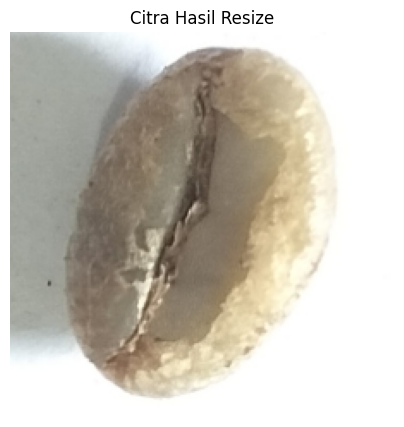

Red (R)        : 195.6769
Green (G)      : 189.6373
Blue (B)       : 177.4900
Contrast       : 48.9948
Energy         : 0.2930
Homogeneity    : 0.5041
Dissimilarity  : 3.1613
Correlation    : 0.9924
ASM            : 0.0858


In [8]:
# PENGGABUNGAN FITUR

fitur = [
    mean_r,
    mean_g,
    mean_b,
    contrast,
    energy,
    homogeneity,
    dissimilarity,
    correlation,
    asm
]

plt.figure(figsize=(5,5))
plt.imshow(cv2.cvtColor(img_resize, cv2.COLOR_BGR2RGB))
plt.title("Citra Hasil Resize")
plt.axis("off")
plt.show()

nama_fitur = [
    "Red (R)",
    "Green (G)",
    "Blue (B)",
    "Contrast",
    "Energy",
    "Homogeneity",
    "Dissimilarity",
    "Correlation",
    "ASM"
]

for nama, nilai in zip(nama_fitur, fitur):
    print(f"{nama:<15}: {nilai:.4f}")

TAHAP KLASIFIKASI SUPPORT VECTOR MACHINE

In [9]:
# MEMBENTUK DATASET FITUR

X = []
Y = []
image_paths = []

for label in ['baik', 'buruk']:

    path = os.path.join("../dataset", label)
    files = os.listdir(path)

    for file in files:

        img_path = os.path.join(path, file)
        img = cv2.imread(img_path)

        if img is None:
            continue

        # PREPROCESSING
        img_resize = cv2.resize(img, (224, 224))
        gray = cv2.cvtColor(img_resize, cv2.COLOR_BGR2GRAY)

        # RGB
        mean_r = np.mean(img_resize[:, :, 2])
        mean_g = np.mean(img_resize[:, :, 1])
        mean_b = np.mean(img_resize[:, :, 0])

        # GLCM
        glcm = graycomatrix(gray, [1], [0], 256, symmetric=True, normed=True)

        contrast = graycoprops(glcm, 'contrast')[0,0]
        energy = graycoprops(glcm, 'energy')[0,0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0,0]
        dissimilarity = graycoprops(glcm, 'dissimilarity')[0,0]
        correlation = graycoprops(glcm, 'correlation')[0,0]
        asm = graycoprops(glcm, 'ASM')[0,0]

        fitur = [
            mean_r,
            mean_g,
            mean_b,
            contrast,
            energy,
            homogeneity,
            dissimilarity,
            correlation,
            asm
        ]

        X.append(fitur)
        image_paths.append(img_path)

        if label == 'baik':
            Y.append(1)
        else:
            Y.append(0)

# SPLIT DATA

X_train, X_test, Y_train, Y_test, train_paths, test_paths = train_test_split(
    X,
    Y,
    image_paths,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("SPLIT DATA")
print("Jumlah Data Training :", len(X_train))
print("Jumlah Data Testing  :", len(X_test))

SPLIT DATA
Jumlah Data Training : 240
Jumlah Data Testing  : 60


In [10]:
# NORMALISASI DATA
X_train_asli = X_train.copy()
X_test_asli = X_test.copy()

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("HASIL NORMALISASI")
print("Data Training :", X_train.shape)
print("Data Testing  :", X_test.shape)

print("\nContoh Data Training Setelah Normalisasi")
print(X_train[:1])

HASIL NORMALISASI
Data Training : (240, 9)
Data Testing  : (60, 9)

Contoh Data Training Setelah Normalisasi
[[ 1.30062367  1.39422449  1.35811054 -1.0001916   0.11758417  1.39743074
  -1.25743443  0.83551478 -0.18060444]]


Model SVM berhasil dilatih.


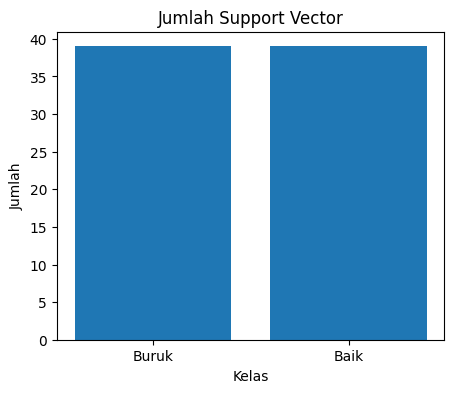

In [11]:
# TRAINING SVM

model = SVC(
    kernel='rbf',
    C=5,
    gamma=0.1
)

model.fit(X_train, Y_train)

kelas = ["Buruk", "Baik"]
jumlah_sv = model.n_support_

print("Model SVM berhasil dilatih.")

plt.figure(figsize=(5,4))
plt.bar(kelas, jumlah_sv)

plt.title("Jumlah Support Vector")
plt.xlabel("Kelas")
plt.ylabel("Jumlah")

plt.show()

=== HASIL KLASIFIKASI DATA TESTING ===
Jumlah Data Testing : 60
Jumlah Hasil Prediksi : 60


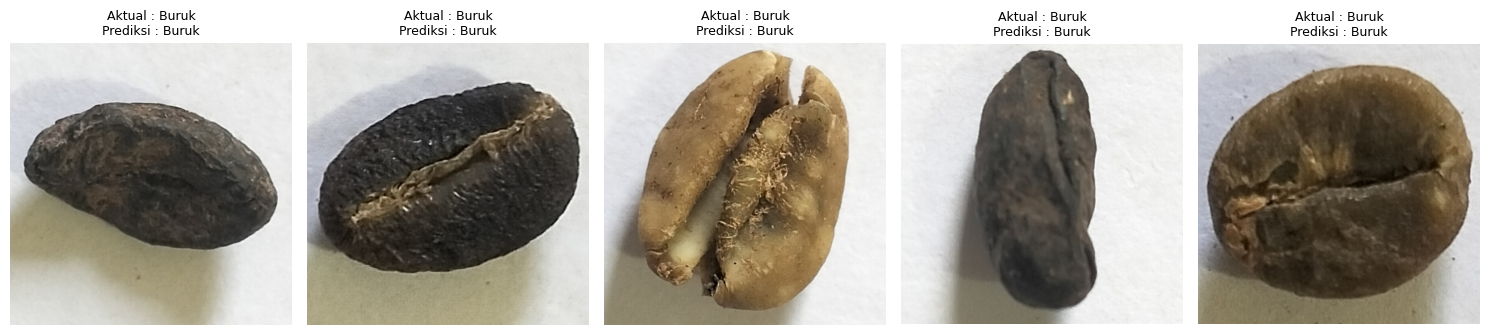

In [12]:
# KLASIFIKASI DATA TESTING

Y_pred = model.predict(X_test)

# KLASIFIKASI DATA TESTING

print("=== HASIL KLASIFIKASI DATA TESTING ===")
print(f"Jumlah Data Testing : {len(Y_test)}")
print(f"Jumlah Hasil Prediksi : {len(Y_pred)}")

# Menampilkan 5 data testing pertama
plt.figure(figsize=(15,8))

for i in range(5):

    # Ambil gambar asli data testing
    img = cv2.imread(test_paths[i])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    aktual = "Baik" if Y_test[i] == 1 else "Buruk"
    prediksi = "Baik" if Y_pred[i] == 1 else "Buruk"

    plt.subplot(1,5,i+1)
    plt.imshow(img_rgb)
    plt.title(f"Aktual : {aktual}\nPrediksi : {prediksi}", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

========== HASIL EVALUASI MODEL ==========



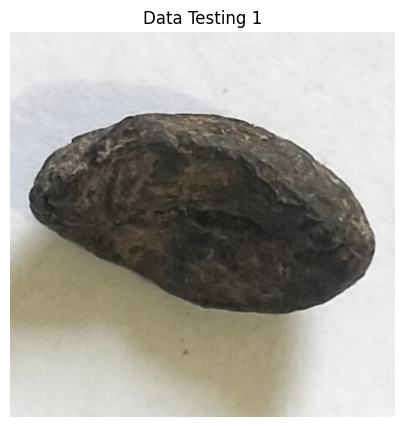

===== DATA TESTING 1 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 160.0946
Green (G)       : 157.8744
Blue (B)        : 149.6462

Fitur Tekstur GLCM
Contrast        : 65.6684
Energy          : 0.0476
Homogeneity     : 0.3737
Dissimilarity   : 3.4002
Correlation     : 0.9940
ASM             : 0.0023
--------------------------------------------------


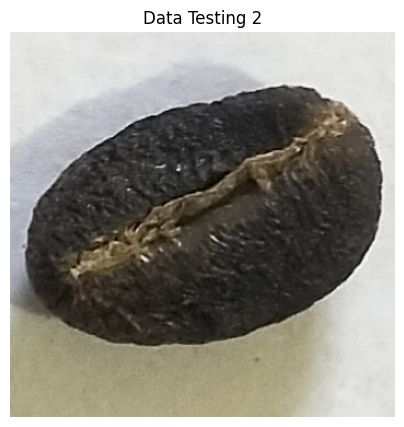

===== DATA TESTING 2 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 130.4812
Green (G)       : 127.7425
Blue (B)        : 118.9858

Fitur Tekstur GLCM
Contrast        : 117.9606
Energy          : 0.0330
Homogeneity     : 0.2934
Dissimilarity   : 4.9618
Correlation     : 0.9898
ASM             : 0.0011
--------------------------------------------------


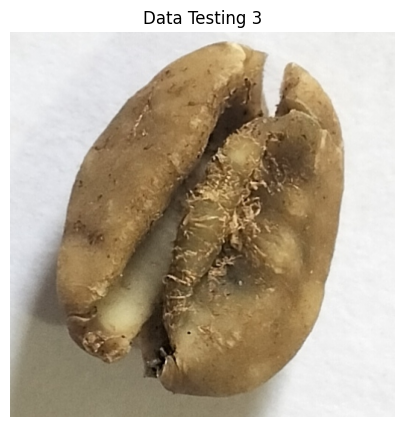

===== DATA TESTING 3 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 173.9408
Green (G)       : 159.3303
Blue (B)        : 137.5241

Fitur Tekstur GLCM
Contrast        : 170.5213
Energy          : 0.0398
Homogeneity     : 0.2924
Dissimilarity   : 6.4115
Correlation     : 0.9777
ASM             : 0.0016
--------------------------------------------------


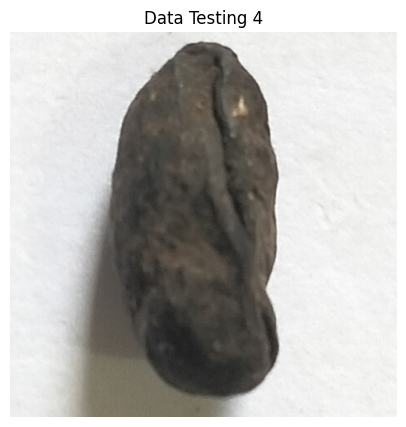

===== DATA TESTING 4 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 174.3664
Green (G)       : 172.7856
Blue (B)        : 169.5757

Fitur Tekstur GLCM
Contrast        : 91.3614
Energy          : 0.0545
Homogeneity     : 0.3499
Dissimilarity   : 3.5423
Correlation     : 0.9927
ASM             : 0.0030
--------------------------------------------------


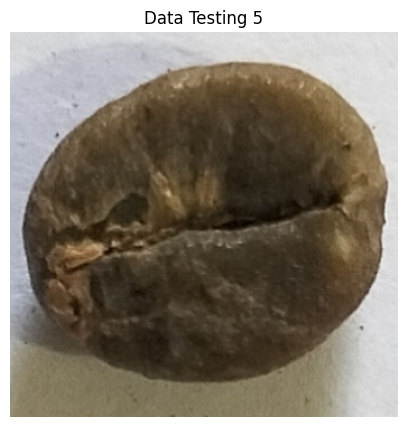

===== DATA TESTING 5 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 118.1007
Green (G)       : 108.1441
Blue (B)        : 93.1500

Fitur Tekstur GLCM
Contrast        : 62.7705
Energy          : 0.0252
Homogeneity     : 0.2842
Dissimilarity   : 4.1521
Correlation     : 0.9920
ASM             : 0.0006
--------------------------------------------------


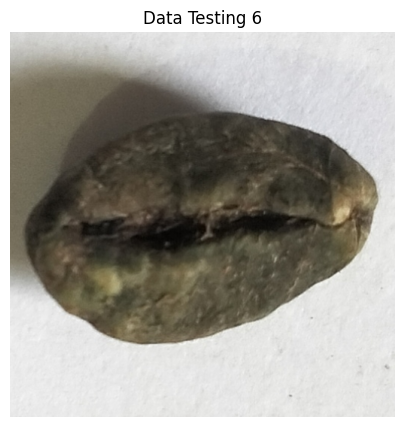

===== DATA TESTING 6 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 150.8118
Green (G)       : 147.6141
Blue (B)        : 139.4787

Fitur Tekstur GLCM
Contrast        : 49.0137
Energy          : 0.0358
Homogeneity     : 0.2844
Dissimilarity   : 3.9009
Correlation     : 0.9958
ASM             : 0.0013
--------------------------------------------------


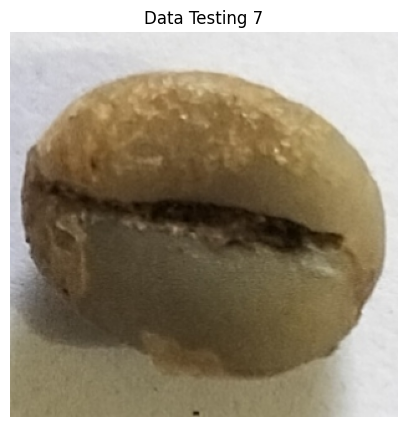

===== DATA TESTING 7 =====
Label Asli      : Baik
Hasil Prediksi  : Baik

Fitur Warna RGB
Red (R)         : 143.1647
Green (G)       : 130.7310
Blue (B)        : 108.2023

Fitur Tekstur GLCM
Contrast        : 32.0645
Energy          : 0.0312
Homogeneity     : 0.3419
Dissimilarity   : 3.1443
Correlation     : 0.9957
ASM             : 0.0010
--------------------------------------------------


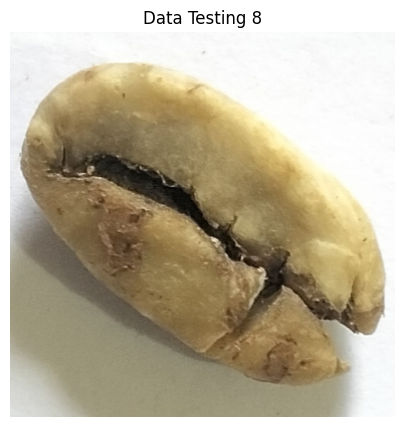

===== DATA TESTING 8 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 176.9971
Green (G)       : 165.2686
Blue (B)        : 138.2824

Fitur Tekstur GLCM
Contrast        : 73.6301
Energy          : 0.0464
Homogeneity     : 0.3326
Dissimilarity   : 4.2618
Correlation     : 0.9901
ASM             : 0.0022
--------------------------------------------------


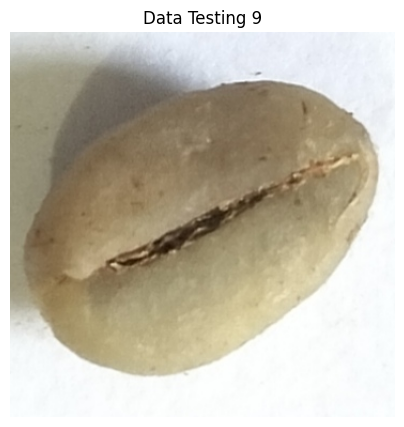

===== DATA TESTING 9 =====
Label Asli      : Baik
Hasil Prediksi  : Baik

Fitur Warna RGB
Red (R)         : 187.6136
Green (G)       : 180.1154
Blue (B)        : 161.8520

Fitur Tekstur GLCM
Contrast        : 24.3807
Energy          : 0.0602
Homogeneity     : 0.4224
Dissimilarity   : 2.5753
Correlation     : 0.9961
ASM             : 0.0036
--------------------------------------------------


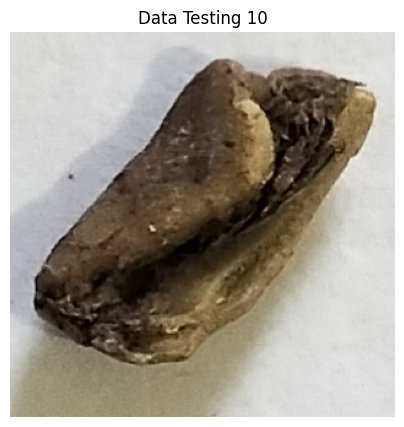

===== DATA TESTING 10 =====
Label Asli      : Buruk
Hasil Prediksi  : Buruk

Fitur Warna RGB
Red (R)         : 151.2965
Green (G)       : 143.5477
Blue (B)        : 131.3389

Fitur Tekstur GLCM
Contrast        : 92.6076
Energy          : 0.0381
Homogeneity     : 0.3019
Dissimilarity   : 4.7902
Correlation     : 0.9906
ASM             : 0.0015
--------------------------------------------------


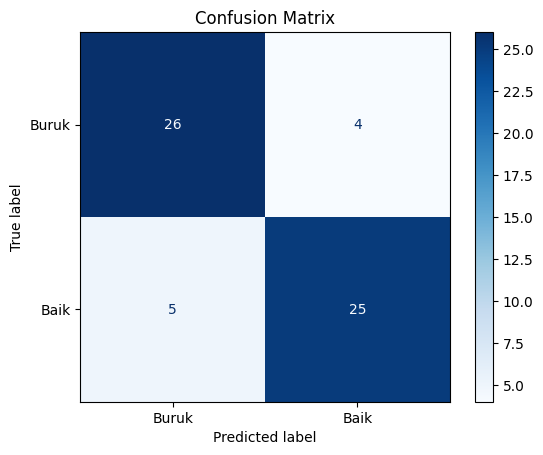


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

       Buruk       0.84      0.87      0.85        30
        Baik       0.86      0.83      0.85        30

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60

========== HASIL EVALUASI ==========

Accuracy  : 85.00%
Precision : 86.21%
Recall    : 83.33%
F1-Score  : 84.75%


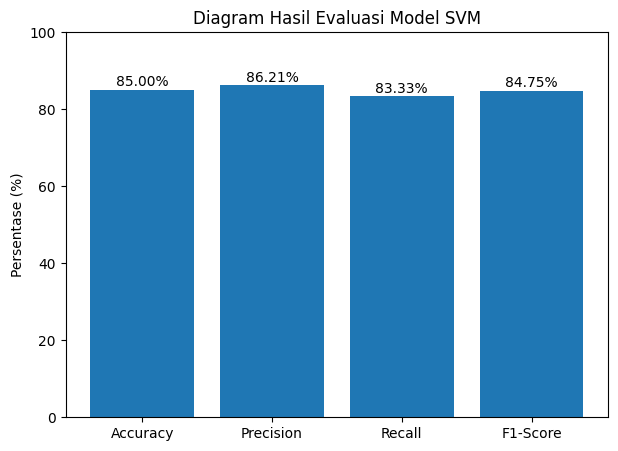

In [13]:
# ===============================
# EVALUASI MODEL
# ===============================

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)

cm = confusion_matrix(Y_test, Y_pred)

print("========== HASIL EVALUASI MODEL ==========\n")

# ===============================
# MENAMPILKAN 2 DATA TESTING
# ===============================

for i in range(10):

    img = cv2.imread(test_paths[i])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(f"Data Testing {i+1}")
    plt.axis("off")
    plt.show()

    print(f"===== DATA TESTING {i+1} =====")

    print("Label Asli      :", "Baik" if Y_test[i] == 1 else "Buruk")
    print("Hasil Prediksi  :", "Baik" if Y_pred[i] == 1 else "Buruk")

    print("\nFitur Warna RGB")
    print(f"Red (R)         : {X_test_asli[i][0]:.4f}")
    print(f"Green (G)       : {X_test_asli[i][1]:.4f}")
    print(f"Blue (B)        : {X_test_asli[i][2]:.4f}")

    print("\nFitur Tekstur GLCM")
    print(f"Contrast        : {X_test_asli[i][3]:.4f}")
    print(f"Energy          : {X_test_asli[i][4]:.4f}")
    print(f"Homogeneity     : {X_test_asli[i][5]:.4f}")
    print(f"Dissimilarity   : {X_test_asli[i][6]:.4f}")
    print(f"Correlation     : {X_test_asli[i][7]:.4f}")
    print(f"ASM             : {X_test_asli[i][8]:.4f}")

    print("-"*50)


# ===============================
# CONFUSION MATRIX
# ===============================

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Buruk","Baik"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


# ===============================
# CLASSIFICATION REPORT
# ===============================

print("\n========== CLASSIFICATION REPORT ==========\n")

print(classification_report(
    Y_test,
    Y_pred,
    target_names=["Buruk","Baik"]
))


# ===============================
# HASIL EVALUASI
# ===============================

print("========== HASIL EVALUASI ==========\n")

print(f"Accuracy  : {accuracy*100:.2f}%")
print(f"Precision : {precision*100:.2f}%")
print(f"Recall    : {recall*100:.2f}%")
print(f"F1-Score  : {f1*100:.2f}%")


# ===============================
# DIAGRAM HASIL EVALUASI
# ===============================

metrik = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

nilai = [
    accuracy*100,
    precision*100,
    recall*100,
    f1*100
]

plt.figure(figsize=(7,5))

bars = plt.bar(metrik, nilai)

plt.ylim(0,100)

plt.ylabel("Persentase (%)")
plt.title("Diagram Hasil Evaluasi Model SVM")

for bar in bars:

    tinggi = bar.get_height()

    plt.text(
        bar.get_x()+bar.get_width()/2,
        tinggi+1,
        f"{tinggi:.2f}%",
        ha='center'
    )

plt.show()